# 🧪 06 - Visualization Lab: The Penguin Report, in Pictures

In the Module 07 lab you described the Palmer Penguins with **numbers**: a data dictionary, summary tables, outliers within species, and a Simpson's paradox in the bill measurements. Now the research team wants a **visual report**: a small set of figures that tells the same story to someone who'll never read a table.

You'll build it with everything from notebooks 01–05, check each figure against your Module 07 numbers, and save a finished figure set.

## ✅ Learning Goals
- Turn a numeric finding into the chart that shows it best
- Use one consistent, colorblind-safe palette and category order across a whole report
- Build single charts, small multiples, and a multi-panel summary figure
- Write titles that state findings, and check every chart against the numbers
- Export a complete, labeled figure set

```text
Load & clean (Module 07 lab) → Set report style → Distributions (03)
     → Group comparisons (03, 04) → Composition (02) → Relationships (04)
     → The paradox (04) → Summary figure (01) → Export
```

## 0. Setup
Everything this lab saves goes into **`06-OutputFiles`**. Upload that folder along with this notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

OUT = Path('06-OutputFiles')
OUT.mkdir(exist_ok=True)

MEASUREMENTS = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']

# Same cleaning as the Module 07 lab
penguins = pd.read_csv('penguins.csv').dropna(subset=MEASUREMENTS).copy()
penguins['sex'] = penguins['sex'].str.title()
print(penguins.shape)

(342, 7)


## 1. Set the Report Style Once
A report looks like **one** report when every chart uses the same theme, the same category order, and the same color for the same species (notebook 05). Define them once, at the top, and use them everywhere:

In [2]:
sns.set_theme(style='whitegrid', context='notebook')

SPECIES = ['Adelie', 'Chinstrap', 'Gentoo']
SPECIES_COLORS = dict(zip(SPECIES, sns.color_palette('colorblind', 3)))
SEX_COLORS = {'Female': '#999999', 'Male': '#333333'}

LABELS = {
    'bill_length_mm': 'Bill length (mm)',
    'bill_depth_mm': 'Bill depth (mm)',
    'flipper_length_mm': 'Flipper length (mm)',
    'body_mass_g': 'Body mass (g)',
}


def finish(ax, title, subtitle=None):
    """Apply the report's title style to an ax (notebook 05)."""
    ax.set_title(title, loc='left', fontweight='bold', pad=22 if subtitle else 6)
    if subtitle:
        ax.text(0, 1.02, subtitle, transform=ax.transAxes, color='gray')
    ax.spines[['top', 'right']].set_visible(False)

np.random.seed(21)
KNOWN_SEX = penguins.loc[penguins['sex'].notna()].copy()
SEX_ORDER = ['Female', 'Male']


`finish()` is notebook 01's "functions that draw on an `ax`" idea: every chart gets the same title style with one line.

## 2. Figure 1: Two Groups Hiding in One Distribution
**Module 07 finding:** body mass is roughly symmetric overall (skew ≈ 0.47), and Gentoos are about 1,350 g heavier than the other two species.

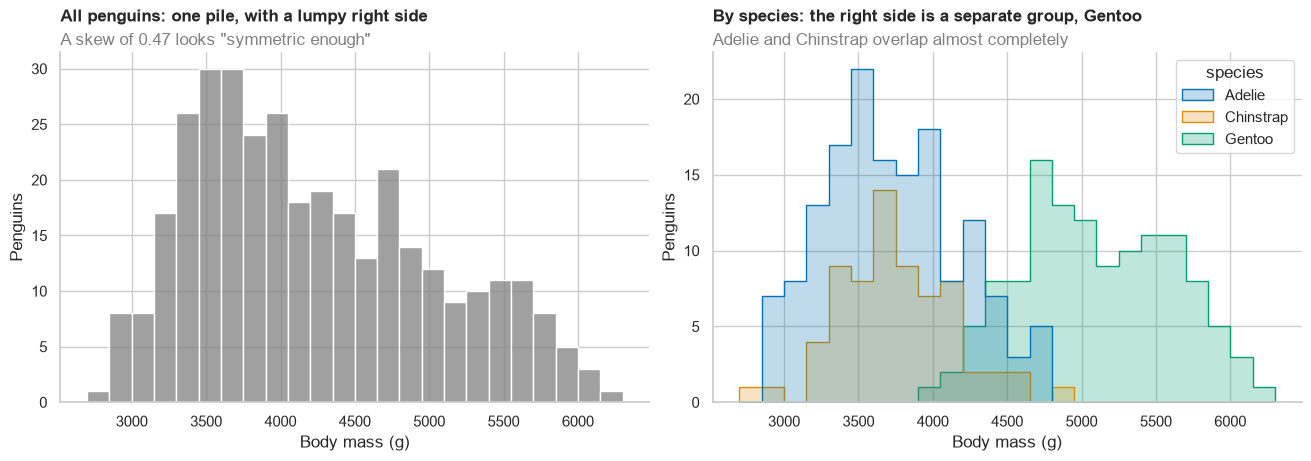

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharex=True, layout='constrained')

sns.histplot(data=penguins, x='body_mass_g', binwidth=150, color='gray', ax=axes[0])
finish(axes[0], 'All penguins: one pile, with a lumpy right side', 'A skew of 0.47 looks "symmetric enough"')

sns.histplot(data=penguins, x='body_mass_g', hue='species', hue_order=SPECIES,
             palette=SPECIES_COLORS, binwidth=150, element='step', ax=axes[1])
finish(axes[1], 'By species: the right side is a separate group, Gentoo', 'Adelie and Chinstrap overlap almost completely')

for ax in axes:
    ax.set(xlabel=LABELS['body_mass_g'], ylabel='Penguins')

fig.savefig(OUT / 'fig1_body_mass_distribution.png', dpi=150, bbox_inches='tight')
plt.show()

✅ **Check against the numbers:** the Gentoo group should center near the Module 07 Gentoo mean (about 5,076 g), and the Adelie/Chinstrap humps near 3,700 g. Do they?

## 3. Figure 2: Species and Sex
**Module 07 finding:** within every species, males are heavier (by about 400–800 g).

**Numeric check:** Yes. The species-colored distributions align with mean masses 3,700.66 g (Adelie), 3,733.09 g (Chinstrap), and 5,076.02 g (Gentoo). Gentoo is 1,375.35 g above Adelie and 1,342.93 g above Chinstrap. All 342 measured birds, including nine with unknown sex, contribute.

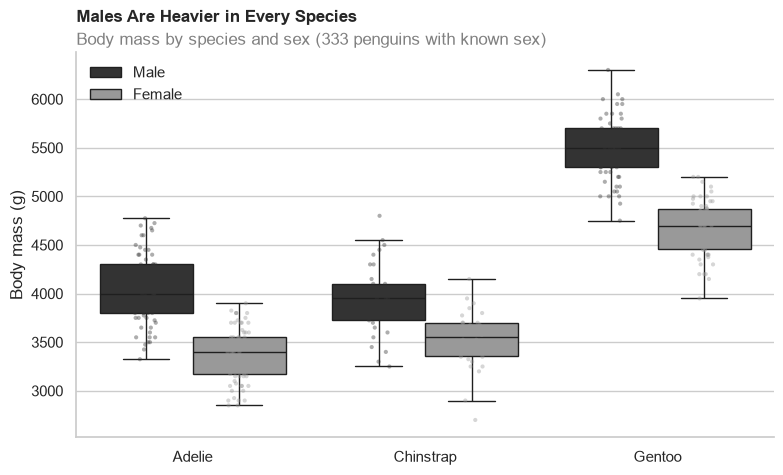

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
sns.boxplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
            order=SPECIES, palette=SEX_COLORS, showfliers=False, ax=ax)
sns.stripplot(data=penguins.dropna(subset=['sex']), x='species', y='body_mass_g', hue='sex',
              order=SPECIES, palette=SEX_COLORS, dodge=True, alpha=0.4, size=3,
              legend=False, ax=ax)
ax.set(xlabel='', ylabel=LABELS['body_mass_g'])
ax.legend(title='', frameon=False, loc='upper left')
finish(ax, 'Males Are Heavier in Every Species',
       f'Body mass by species and sex ({penguins["sex"].notna().sum()} penguins with known sex)')

fig.savefig(OUT / 'fig2_mass_by_species_sex.png', dpi=150, bbox_inches='tight')
plt.show()

The subtitle reports the sample size **after** dropping unknown sex, so the reader knows 9 penguins aren't in this chart (Module 07: always say what a summary is based on).

## 4. Figure 3: Where Each Species Lives
**Module 07 finding:** island and species are tangled together. Chinstraps were only measured on Dream, and Gentoos only on Biscoe.

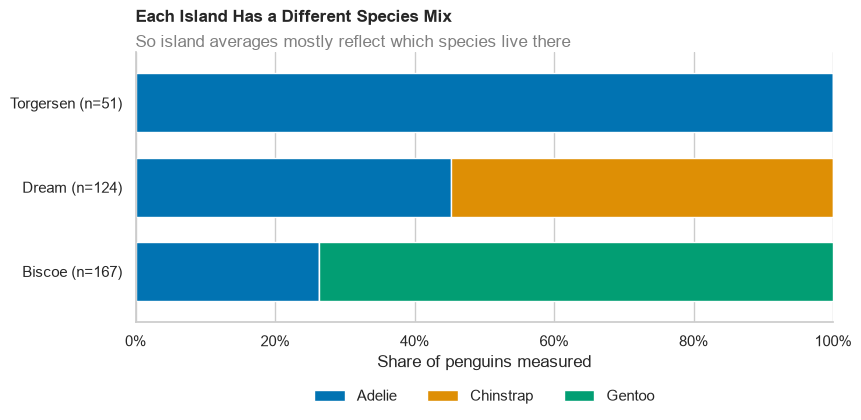

In [5]:
mix = pd.crosstab(penguins['island'], penguins['species'], normalize='index')[SPECIES]
counts = penguins['island'].value_counts()

fig, ax = plt.subplots(figsize=(9, 3.5))
mix.plot.barh(stacked=True, color=[SPECIES_COLORS[s] for s in SPECIES], width=0.7, ax=ax)
ax.set_yticks(range(len(mix)), [f'{island} (n={counts[island]})' for island in mix.index])
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(xmax=1))
ax.set(xlabel='Share of penguins measured', ylabel='')
ax.legend(title='', frameon=False, ncols=3, loc='upper center', bbox_to_anchor=(0.5, -0.2))
finish(ax, 'Each Island Has a Different Species Mix',
       'So island averages mostly reflect which species live there')

fig.savefig(OUT / 'fig3_species_by_island.png', dpi=150, bbox_inches='tight')
plt.show()

## 5. Figure 4: How the Measurements Relate
**Module 07 finding:** flipper length and body mass are very strongly correlated (r ≈ 0.87).

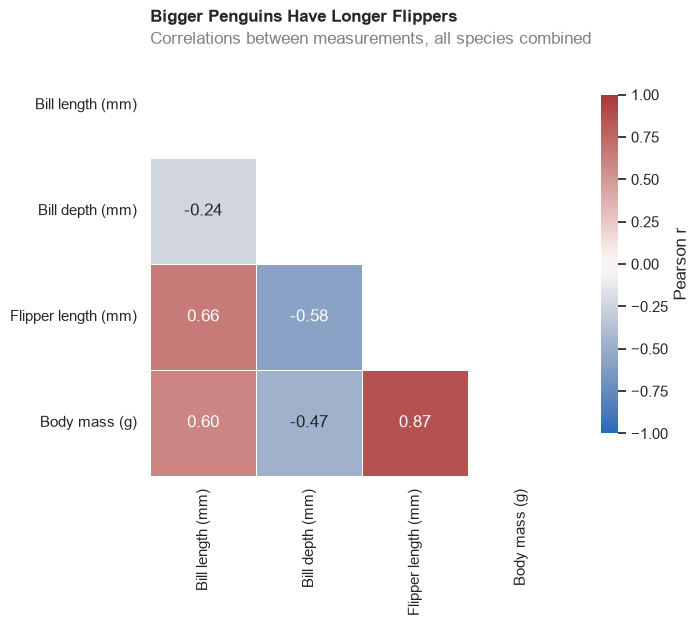

In [6]:
corr = penguins[MEASUREMENTS].rename(columns=LABELS).corr()
mask = np.triu(np.ones(corr.shape, dtype=bool))

fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='vlag', vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, cbar_kws={'label': 'Pearson r', 'shrink': 0.8}, ax=ax)
finish(ax, 'Bigger Penguins Have Longer Flippers', 'Correlations between measurements, all species combined')
ax.spines[['left', 'bottom']].set_visible(False)
ax.grid(False)        # the whitegrid theme would draw lines through the masked cells

fig.savefig(OUT / 'fig4_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

Notice the subtitle: **all species combined.** You know from Module 07 that one of these numbers changes sign within species. That's the next figure, and it's yours to build.

---
## 🛠️ Your Figures
Sections 2–5 were worked examples. Sections 6 and 7 are yours. Use `SPECIES_COLORS`, `SPECIES`, `LABELS`, and `finish()` so they match the rest of the report.

## 6. Figure 5: The Paradox
Build a two-panel figure (`sharex=True, sharey=True`) of bill length vs. bill depth:
- **Left:** all penguins in gray, with one `regplot` trend line and the overall r in the subtitle.
- **Right:** colored by species, with one `regplot` line per species and each species' r in the legend.
- Titles that **state** the finding (for example, "Combined, Longer Bills Look Shallower" / "Within Every Species, Longer Bills Are Deeper").
- Save as `OUT / 'fig5_bill_paradox.png'`.

(Notebook 04 section 3 is your model, but use this report's style.)

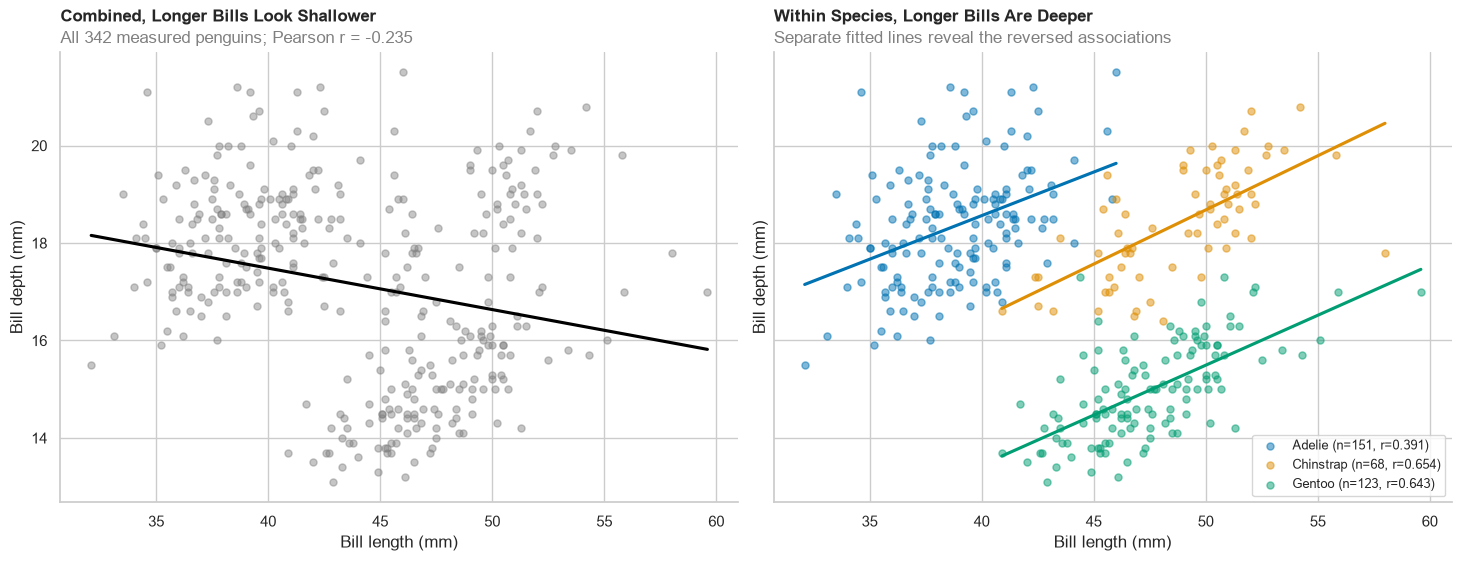

In [7]:
# Your Figure 5 here

r_overall = penguins['bill_length_mm'].corr(penguins['bill_depth_mm'])
species_r = penguins.groupby('species').apply(
    lambda g: g['bill_length_mm'].corr(g['bill_depth_mm']), include_groups=False)
fig, axes = plt.subplots(1, 2, figsize=(14.5, 5.5), sharex=True, sharey=True, layout='constrained')
sns.regplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', ax=axes[0],
            color='gray', scatter_kws={'alpha':.45,'s':26}, line_kws={'color':'black'}, ci=None)
finish(axes[0], 'Combined, Longer Bills Look Shallower', f'All 342 measured penguins; Pearson r = {r_overall:.3f}')
for species in SPECIES:
    group = penguins.loc[penguins.species == species]
    sns.regplot(data=group, x='bill_length_mm', y='bill_depth_mm', ax=axes[1],
                color=SPECIES_COLORS[species], scatter_kws={'alpha':.5,'s':26}, ci=None,
                label=f'{species} (n={len(group)}, r={species_r[species]:.3f})')
finish(axes[1], 'Within Species, Longer Bills Are Deeper', 'Separate fitted lines reveal the reversed associations')
axes[1].legend(fontsize=9, loc='lower right')
for ax in axes:
    ax.set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])
fig.savefig(OUT / 'fig5_bill_paradox.png', dpi=150, bbox_inches='tight')
plt.show()


## 7. Figure 6: The One-Page Summary
Build a single summary figure with `plt.subplot_mosaic()` (notebook 01 Challenge). The skeleton below creates the layout. Fill in each panel:
- `'dist'`: body mass by species (KDE or step histogram)
- `'paradox'`: the species-colored bill scatter from Figure 5
- `'flipper'`: flipper length vs. body mass, colored by species
- `'sex'`: mean body mass by species and sex (`barplot` or `pointplot`)

Give the figure a `suptitle` with the single most important finding, and save it as `OUT / 'fig6_summary.png'`.

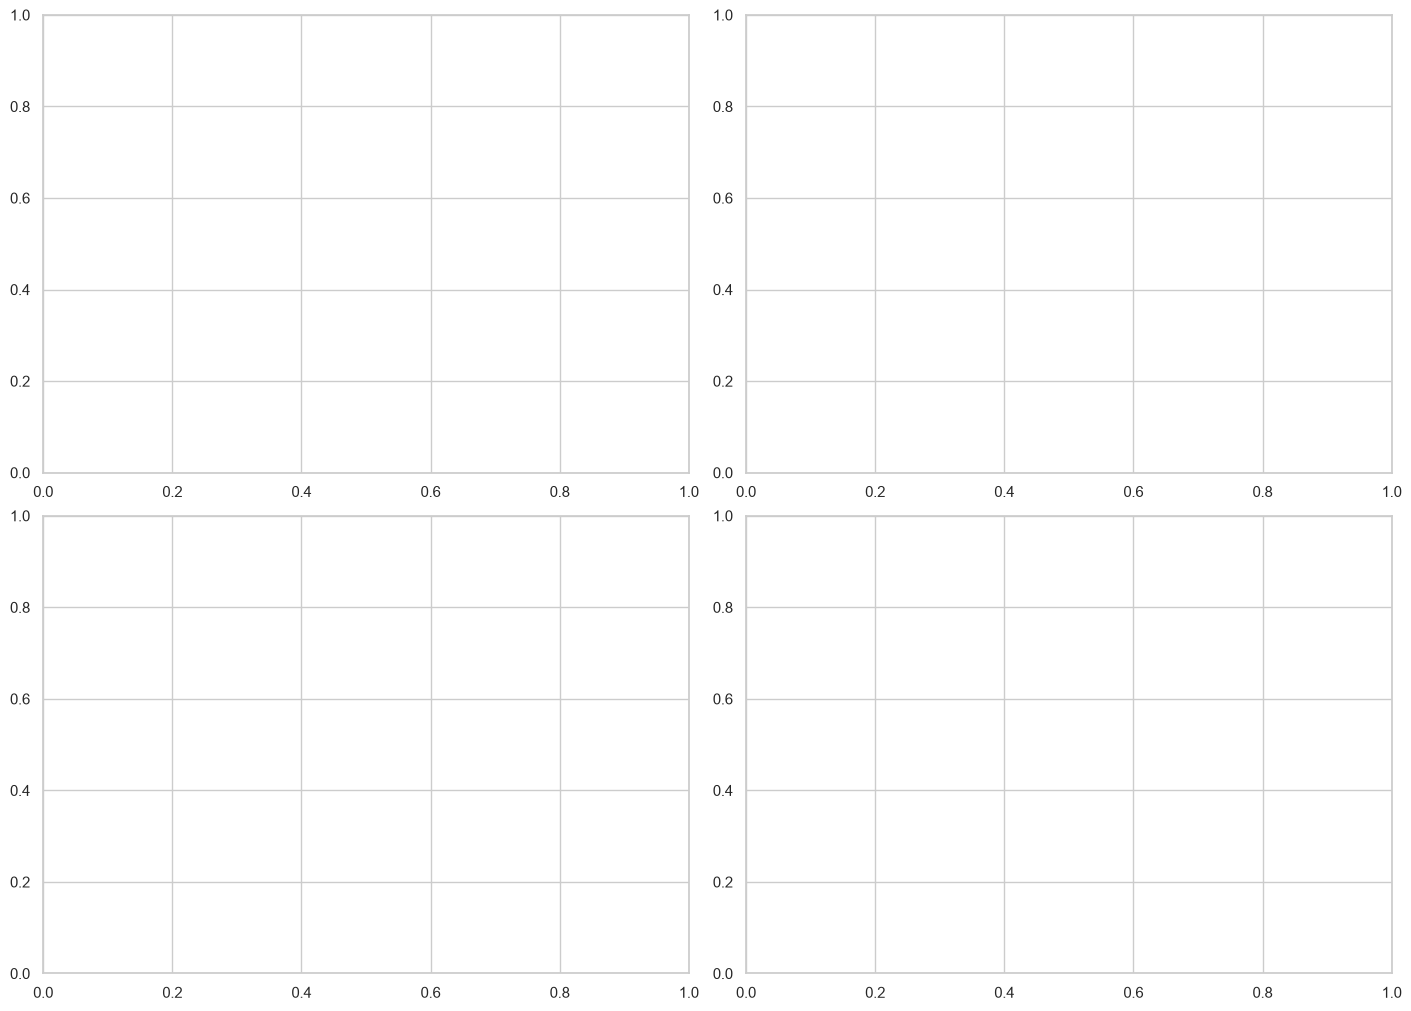

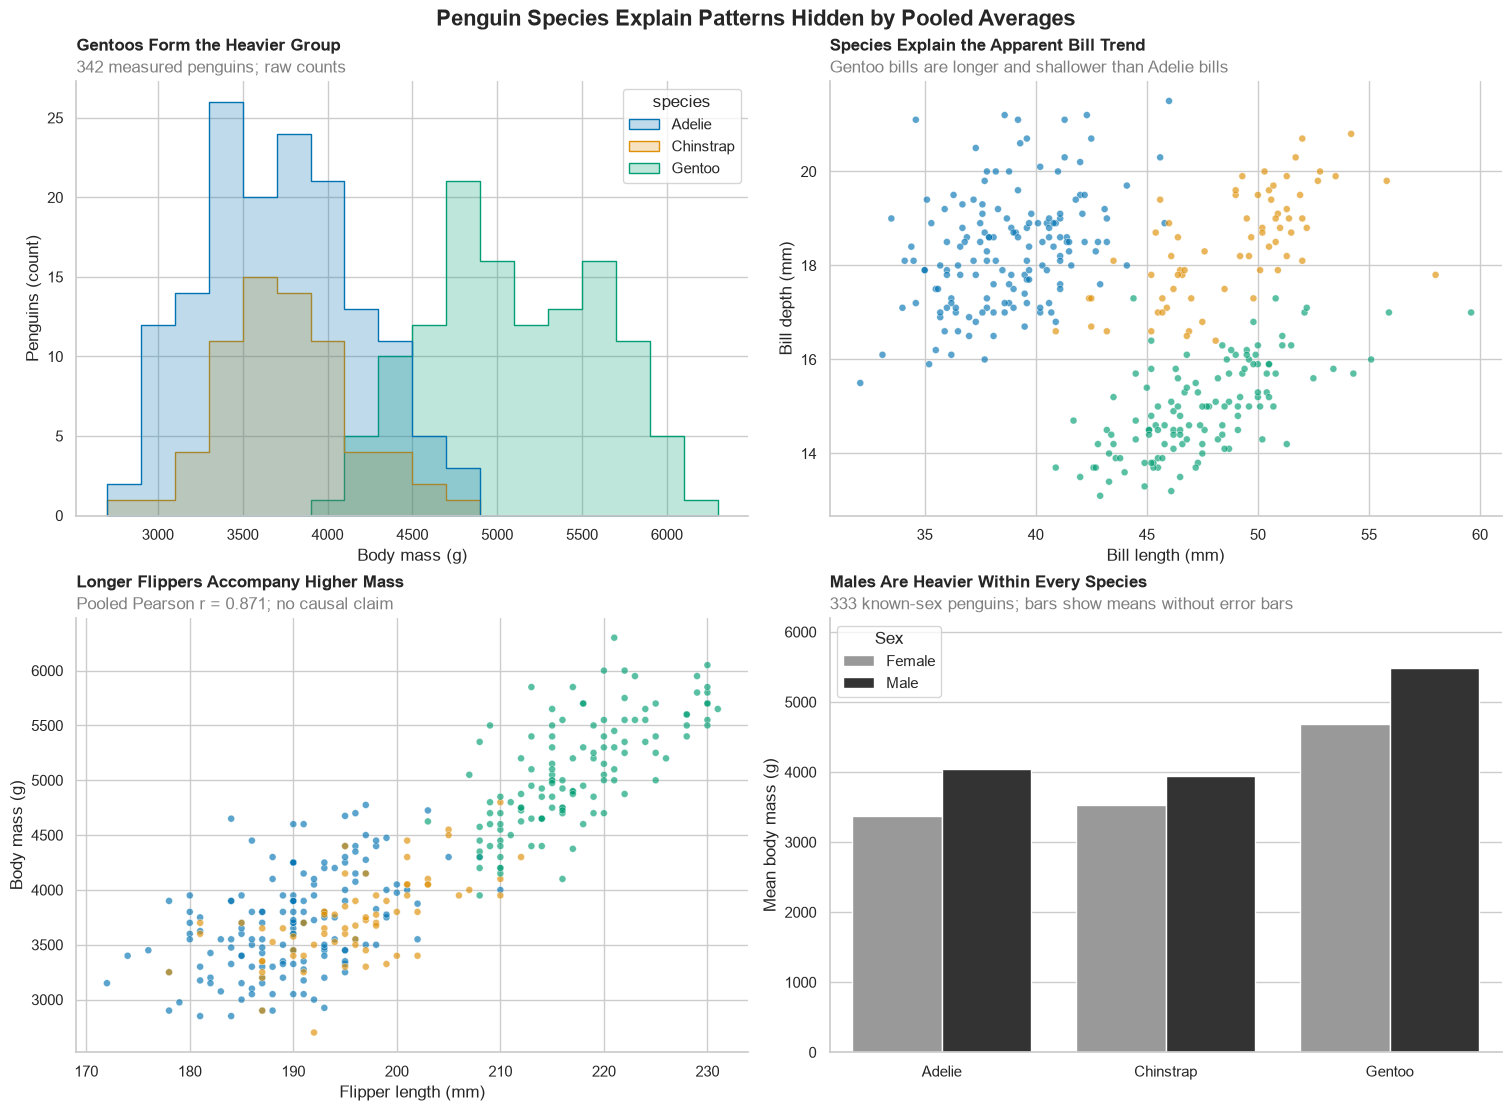

In [8]:
fig, axd = plt.subplot_mosaic(
    [['dist', 'paradox'],
     ['flipper', 'sex']],
    figsize=(14, 10), layout='constrained',
)

# TODO: draw on axd['dist'], axd['paradox'], axd['flipper'], and axd['sex']
# TODO: fig.suptitle(...)
# TODO: fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')

plt.show()

# Complete the instructor's mosaic below; close its empty preview first.
plt.close(fig)
fig, axd = plt.subplot_mosaic([['dist', 'paradox'], ['flipper', 'sex']],
    figsize=(15, 11), layout='constrained')
sns.histplot(data=penguins, x='body_mass_g', hue='species', hue_order=SPECIES,
    palette=SPECIES_COLORS, element='step', binwidth=200, ax=axd['dist'])
axd['dist'].set(xlabel=LABELS['body_mass_g'], ylabel='Penguins (count)')
finish(axd['dist'], 'Gentoos Form the Heavier Group', '342 measured penguins; raw counts')
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species',
    hue_order=SPECIES, palette=SPECIES_COLORS, alpha=.65, s=25, legend=False, ax=axd['paradox'])
axd['paradox'].set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])
finish(axd['paradox'], 'Species Explain the Apparent Bill Trend', 'Gentoo bills are longer and shallower than Adelie bills')
sns.scatterplot(data=penguins, x='flipper_length_mm', y='body_mass_g', hue='species',
    hue_order=SPECIES, palette=SPECIES_COLORS, alpha=.65, s=25, legend=False, ax=axd['flipper'])
axd['flipper'].set(xlabel=LABELS['flipper_length_mm'], ylabel=LABELS['body_mass_g'])
finish(axd['flipper'], 'Longer Flippers Accompany Higher Mass', 'Pooled Pearson r = 0.871; no causal claim')
sns.barplot(data=KNOWN_SEX, x='species', y='body_mass_g', hue='sex', order=SPECIES,
    hue_order=SEX_ORDER, palette=SEX_COLORS, errorbar=None, ax=axd['sex'])
axd['sex'].set(xlabel='', ylabel='Mean body mass (g)', ylim=(0,6200))
axd['sex'].legend(title='Sex', loc='upper left')
finish(axd['sex'], 'Males Are Heavier Within Every Species', '333 known-sex penguins; bars show means without error bars')
fig.suptitle('Penguin Species Explain Patterns Hidden by Pooled Averages', fontsize=16, fontweight='bold')
fig.savefig(OUT / 'fig6_summary.png', dpi=150, bbox_inches='tight')
plt.show()


## ❓ Lab Questions
Answer each in the Markdown cell below:
1. Figure 1: why did a skew of 0.47 (Module 07) fail to warn you that two groups were mixed together? What kind of chart reveals it, and what kind of statistic can't?
2. Figure 2: why does the chart use `showfliers=False` on the box plot? What would go wrong without it?
3. Figure 3: why is a 100% stacked bar a better choice here than a grouped count bar chart? What did adding `n=` to the labels fix?
4. Figure 5: explain Simpson's paradox from your chart alone, as if to someone who has never seen the numbers.
5. Which was easier to **find** the paradox with: the Module 07 tables or the Module 08 chart? Which is better as **evidence**? Why might you want both?
6. Pick one figure and go through the notebook 05 checklist. Which item did you have to fix last?

*Your answers here.*

**Responses:**

1. Skew describes overall asymmetry with one number; it does not identify a mixture of different populations. The species-colored histogram separates the Gentoo hump around 5,076 g from Adelie and Chinstrap around 3,701 and 3,733 g. A single skew, mean, or median cannot reveal those different distributions by itself.
2. The strip layer already shows every measured known-sex penguin, including those beyond box-plot fences. `showfliers=False` avoids adding a second dot for each such outlier; it does not remove those birds from the data.
3. The normalized bars compare species composition without making large island samples dominate by sheer count. Adding n shows that equal total bar lengths represent different samples: Biscoe 167, Dream 124, Torgersen 51. Without n, the reader could mistake equal proportions for equal evidence.
4. The gray pooled line slopes downward because the long, shallow-billed Gentoo cluster is lower and farther right than the other species. Once colors distinguish species, every species-specific line slopes upward. Group differences reverse the combined association: Simpson's paradox. These fitted lines describe associations and do not establish causation.
5. **Technical comparison; personal preference pending:** The colored chart makes the group structure and reversal visually immediate, while the Module 07 table supplies precise correlations: pooled −0.235053, Adelie +0.391492, Chinstrap +0.653536, Gentoo +0.643384. Using both shows the pattern and verifies its magnitude and sample sizes. Inuka's own statement about which was easier for him to discover the paradox remains pending.
6. **Assistant checklist audit; personal reflection pending:** For Figure 7, the question is how bill dimensions separate species; the scatter type fits two numeric variables; the title states the finding; axes show millimeters; the subtitle gives n=342; all species use the report colors; direct labels replace a legend; and the chart retains overlapping and unusual observations. Label placement and whitespace were checked visually after rendering. Inuka's own statement about which checklist item he fixed last remains pending.


## 🏋️ Practice

### Practice 1 — Flipper Length by Species (easy)
Make a violin plot of `flipper_length_mm` by species, with `order=SPECIES` and `palette=SPECIES_COLORS`. Write a title that states the finding, using `finish()`.

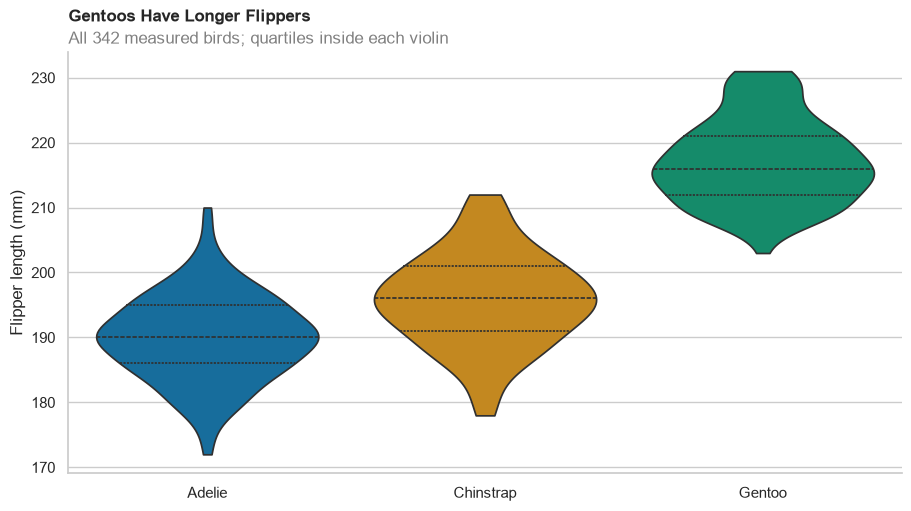

In [9]:
# Your code here

fig, ax = plt.subplots(figsize=(9,5), layout='constrained')
sns.violinplot(data=penguins, x='species', y='flipper_length_mm', hue='species',
    order=SPECIES, hue_order=SPECIES, palette=SPECIES_COLORS, legend=False,
    inner='quart', cut=0, ax=ax)
ax.set(xlabel='', ylabel=LABELS['flipper_length_mm'])
finish(ax, 'Gentoos Have Longer Flippers', 'All 342 measured birds; quartiles inside each violin')
fig.savefig(OUT / 'practice_flipper_violin.png', dpi=150, bbox_inches='tight')
plt.show()


### Practice 2 — Small Multiples (medium)
Use `sns.displot()` to draw `bill_depth_mm` with `col='species'` and `hue='sex'`, using the report's colors and order. Save it as `OUT / 'practice_bill_depth_grid.png'`.

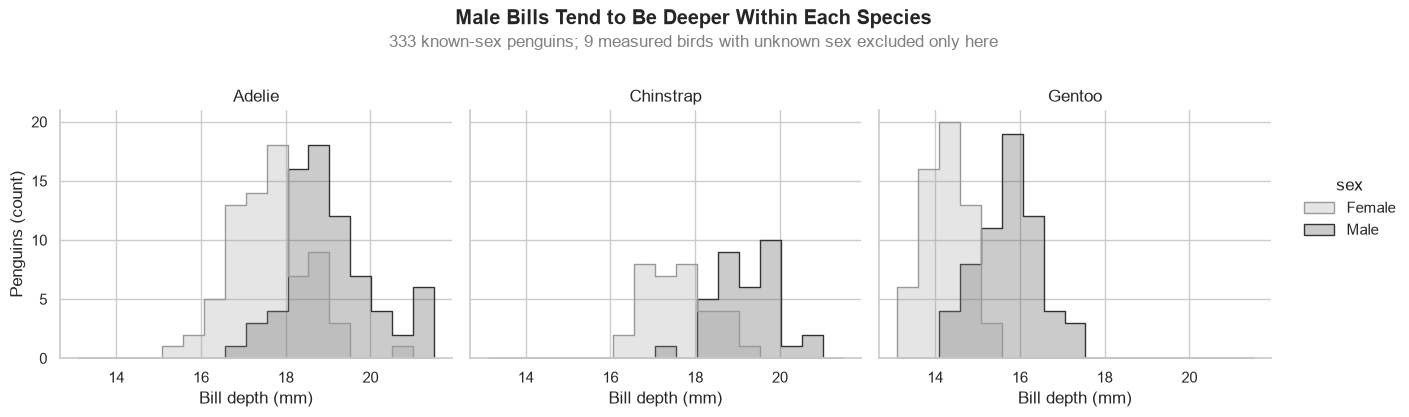

In [10]:
# Your code here

g = sns.displot(data=KNOWN_SEX, x='bill_depth_mm', col='species', hue='sex',
    col_order=SPECIES, hue_order=SEX_ORDER, palette=SEX_COLORS,
    element='step', binwidth=.5, height=4.2, aspect=1.05)
g.set_axis_labels(LABELS['bill_depth_mm'], 'Penguins (count)')
g.set_titles('{col_name}')
g.figure.subplots_adjust(top=.75)
g.figure.suptitle('Male Bills Tend to Be Deeper Within Each Species', y=.99, fontweight='bold')
g.figure.text(.5, .90, '333 known-sex penguins; 9 measured birds with unknown sex excluded only here',
              ha='center', color='gray')
g.savefig(OUT / 'practice_bill_depth_grid.png', dpi=150, bbox_inches='tight')
plt.show()


### Practice 3 — A Fair Island Comparison (harder)
Module 07's lab Practice 2 compared Adelie body mass across islands (the only species on all three). Make the chart version: a box + strip plot of Adelie `body_mass_g` by island, with sample sizes in the tick labels. Does the chart agree with your numbers?

           size      mean  median      std
island                                    
Biscoe       44  3709.659  3750.0  487.734
Dream        56  3688.393  3575.0  455.146
Torgersen    51  3706.373  3700.0  445.108


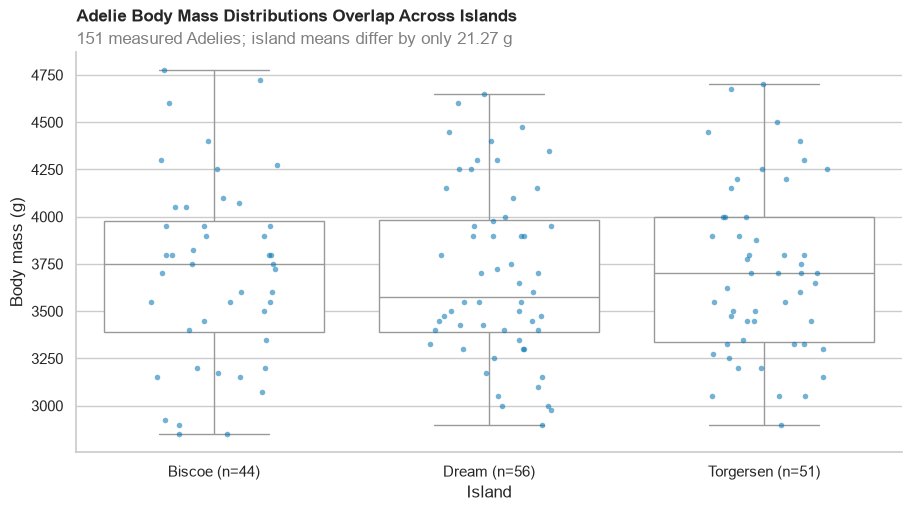

In [11]:
# Your code here

adelie = penguins.loc[penguins.species == 'Adelie']
ISLANDS = ['Biscoe', 'Dream', 'Torgersen']
adelie_stats = adelie.groupby('island')['body_mass_g'].agg(['size','mean','median','std']).reindex(ISLANDS)
print(adelie_stats.round(3).to_string())
fig, ax = plt.subplots(figsize=(9,5), layout='constrained')
sns.boxplot(data=adelie, x='island', y='body_mass_g', order=ISLANDS,
    color='white', showfliers=False, ax=ax)
sns.stripplot(data=adelie, x='island', y='body_mass_g', order=ISLANDS,
    color=SPECIES_COLORS['Adelie'], jitter=.23, alpha=.55, size=4, ax=ax)
ax.set_xticks(range(3), [f'{island} (n={int(adelie_stats.loc[island,"size"])})' for island in ISLANDS])
ax.set(xlabel='Island', ylabel=LABELS['body_mass_g'])
finish(ax, 'Adelie Body Mass Distributions Overlap Across Islands', '151 measured Adelies; island means differ by only 21.27 g')
fig.savefig(OUT / 'practice_adelie_mass_by_island.png', dpi=150, bbox_inches='tight')
plt.show()


**Practice 3 response:** Yes: the distributions overlap strongly. Means are Biscoe 3,709.66 g, Dream 3,688.39 g, and Torgersen 3,706.37 g; their 21.27 g range is small beside within-island sample standard deviations of approximately 445–488 g. The plot supports similar observed masses within Adelie; it does not establish identical populations or absence of every island effect. All 151 measured Adelies contribute, including any with unknown sex.

## ✏️ Challenge Task
Make a **pair plot** of the four measurements with `hue='species'`, `corner=True`, and the report palette. Find the pair of measurements that separates all three species most cleanly, then make a **polished** single scatter plot of just that pair, with a finding title and direct species labels instead of a legend (hint: `ax.text()` at each species' mean position). Save it as `OUT / 'fig7_best_separator.png'`.

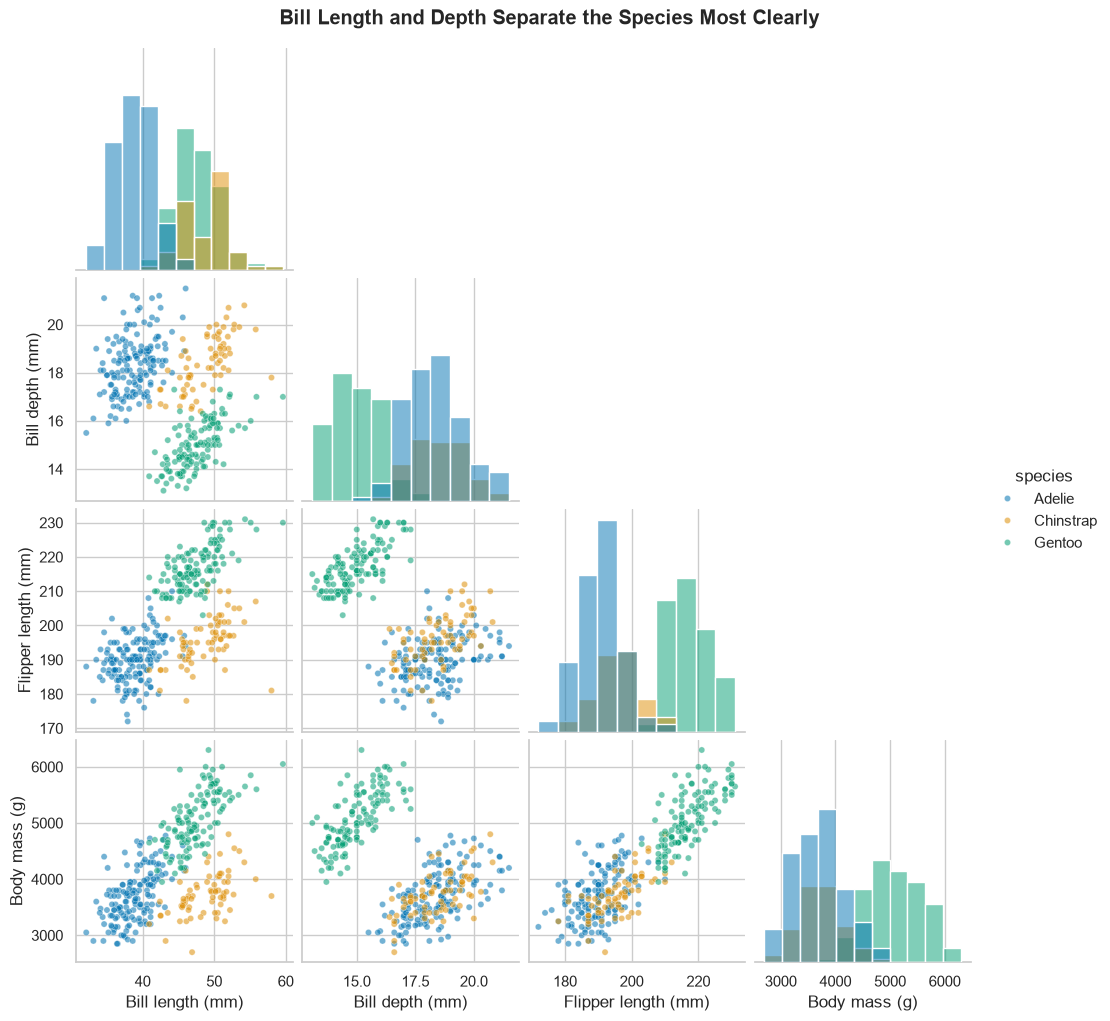

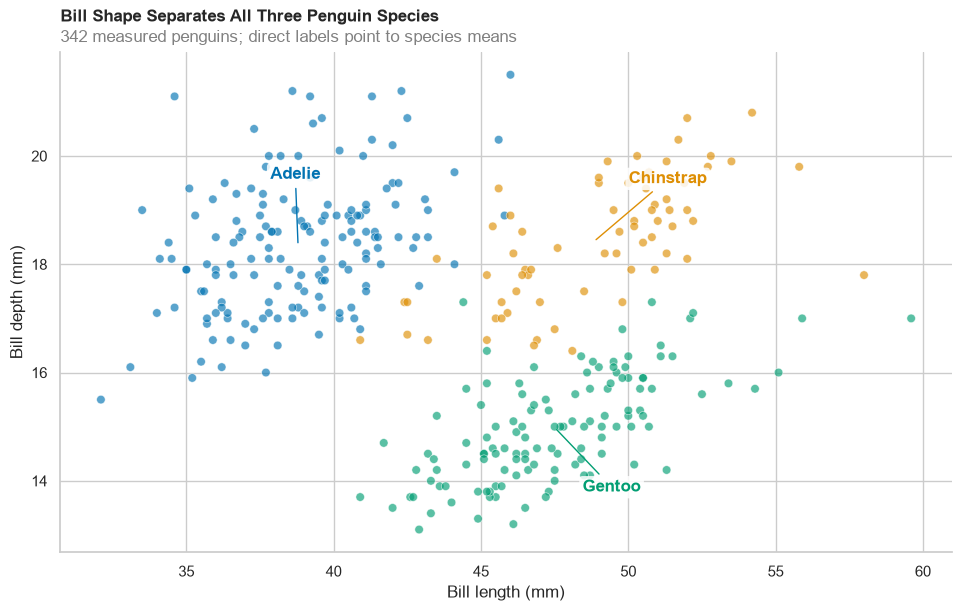

In [12]:
# Your code here

# Explore every measurement pair before choosing a single presentation chart.
pair = sns.pairplot(data=penguins, vars=MEASUREMENTS, hue='species',
    hue_order=SPECIES, palette=SPECIES_COLORS, corner=True, diag_kind='hist',
    plot_kws={'alpha':.55, 's':20}, height=2.5)
for row in pair.axes:
    for ax in row:
        if ax is not None:
            if ax.get_xlabel() in LABELS: ax.set_xlabel(LABELS[ax.get_xlabel()])
            if ax.get_ylabel() in LABELS: ax.set_ylabel(LABELS[ax.get_ylabel()])
pair.figure.suptitle('Bill Length and Depth Separate the Species Most Clearly', y=1.02, fontweight='bold')
pair.savefig(OUT / 'practice_measurement_pairplot.png', dpi=150, bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(9.5,6), layout='constrained')
sns.scatterplot(data=penguins, x='bill_length_mm', y='bill_depth_mm', hue='species',
    hue_order=SPECIES, palette=SPECIES_COLORS, alpha=.65, s=38, legend=False, ax=ax)
centers = penguins.groupby('species')[['bill_length_mm','bill_depth_mm']].mean()
label_offsets = {'Adelie':(-20,48), 'Chinstrap':(25,42), 'Gentoo':(20,-46)}
for species in SPECIES:
    center = centers.loc[species]
    ax.annotate(species, xy=(center.bill_length_mm,center.bill_depth_mm),
        xytext=label_offsets[species], textcoords='offset points',
        color=SPECIES_COLORS[species], fontweight='bold', fontsize=12,
        bbox={'boxstyle':'round,pad=.2','fc':'white','ec':'none','alpha':.85},
        arrowprops={'arrowstyle':'-','color':SPECIES_COLORS[species]})
ax.set(xlabel=LABELS['bill_length_mm'], ylabel=LABELS['bill_depth_mm'])
finish(ax, 'Bill Shape Separates All Three Penguin Species', '342 measured penguins; direct labels point to species means')
fig.savefig(OUT / 'fig7_best_separator.png', dpi=150, bbox_inches='tight')
plt.show()


**Separator response:** Bill length and bill depth jointly distinguish the three species most clearly in this pair plot: Adelie tends toward shorter/deeper bills, Chinstrap toward longer/deeper bills, and Gentoo toward longer/shallower bills. There is some overlap, so this visual choice is not a claim of perfect classification or a validated classifier. Direct labels point to species means and use the same species colors as the other report figures.

## 🔥 Challenge (Optional) — A Visual Report on New Data
Pick `titanic.csv` or `pokemon.csv` (copy it into this folder, or use the path `../07-Describing_Data/`). Ask **three** questions, and answer each with one finished chart (finding title, consistent palette, honest scales), saved to `OUT` with a `challenge_` prefix. Write one sentence per chart summarizing the finding.

In [13]:
# Your code here

*Your three findings here.*

**Optional challenge status:** The new-data visual report remains queued until required course work is finished. No optional findings are asserted.

## 📦 Check Your Output Files
Run this last. Everything you saved should be inside `06-OutputFiles`. Upload that folder along with this notebook.

In [14]:
# Independent checks against raw source rows and the accepted Module 07 results.
raw = pd.read_csv('penguins.csv')
assert len(raw) == 344 and len(penguins) == 342
assert raw[MEASUREMENTS].isna().any(axis=1).sum() == 2
assert raw[MEASUREMENTS].isna().any(axis=1).equals(raw[MEASUREMENTS].isna().all(axis=1))
assert penguins['sex'].isna().sum() == 9 and len(KNOWN_SEX) == 333
assert penguins.groupby('species').size().reindex(SPECIES).tolist() == [151,68,123]
assert KNOWN_SEX.groupby(['species','sex']).size().unstack('sex').reindex(SPECIES)[SEX_ORDER].to_numpy().tolist() == [[73,73],[34,34],[58,61]]
assert penguins.groupby('island').size().reindex(['Biscoe','Dream','Torgersen']).tolist() == [167,124,51]
np.testing.assert_allclose(r_overall,-.2350528703555327)
np.testing.assert_allclose(species_r.reindex(SPECIES),[.39149169183587645,.6535362081800427,.6433839465253384])
np.testing.assert_allclose(np.corrcoef(penguins[MEASUREMENTS].to_numpy().T),corr.to_numpy())
sex_mass = KNOWN_SEX.groupby(['species','sex']).body_mass_g.mean().unstack('sex')
gaps = (sex_mass.Male-sex_mass.Female).reindex(SPECIES)
np.testing.assert_allclose(gaps,[674.6575342465753,411.76470588235316,805.0946862634255])
print('Male minus female mean mass gaps (g):',gaps.to_dict())
from itertools import combinations
reversals = []
for x,y in combinations(MEASUREMENTS,2):
    pooled = np.corrcoef(penguins[x],penguins[y])[0,1]
    grouped = [np.corrcoef(g[x],g[y])[0,1] for _,g in penguins.groupby('species')]
    if all(np.sign(r) != np.sign(pooled) for r in grouped): reversals.append((x,y))
assert len(reversals) == 3
print('Three sign-reversal pairs:', reversals)
expected = {'fig1_body_mass_distribution.png','fig2_mass_by_species_sex.png',
    'fig3_species_by_island.png','fig4_correlation_heatmap.png','fig5_bill_paradox.png',
    'fig6_summary.png','fig7_best_separator.png','practice_flipper_violin.png',
    'practice_bill_depth_grid.png','practice_adelie_mass_by_island.png','practice_measurement_pairplot.png'}
assert {p.name for p in OUT.glob('*.png')} == expected
print('PASS: denominators, correlations, species/sex gaps, reversals, and eleven required figure exports.')


Male minus female mean mass gaps (g): {'Adelie': 674.6575342465753, 'Chinstrap': 411.76470588235316, 'Gentoo': 805.0946862634255}
Three sign-reversal pairs: [('bill_length_mm', 'bill_depth_mm'), ('bill_depth_mm', 'flipper_length_mm'), ('bill_depth_mm', 'body_mass_g')]
PASS: denominators, correlations, species/sex gaps, reversals, and eleven required figure exports.


In [15]:
for path in sorted(OUT.rglob('*')):
    print(path)

06-OutputFiles\fig1_body_mass_distribution.png
06-OutputFiles\fig2_mass_by_species_sex.png
06-OutputFiles\fig3_species_by_island.png
06-OutputFiles\fig4_correlation_heatmap.png
06-OutputFiles\fig5_bill_paradox.png
06-OutputFiles\fig6_summary.png
06-OutputFiles\fig7_best_separator.png
06-OutputFiles\practice_adelie_mass_by_island.png
06-OutputFiles\practice_bill_depth_grid.png
06-OutputFiles\practice_flipper_violin.png
06-OutputFiles\practice_measurement_pairplot.png


---
### 📝 Summary
This lab turned a numeric report into a visual one:
- **One style for the whole report**: a theme, a category order, a palette dictionary, and a `finish()` helper
- **Distributions** revealed a second group that the skew statistic hid
- **Box + strip** showed both the summary and every penguin
- **Composition** made the island/species confounder visible, with sample sizes
- **Heatmap + paradox figure**: the combined correlation, and why it misleads
- **Every chart was checked against the Module 07 numbers**: charts and statistics work best together

🎓 That's Module 08, and the end of the course's core material. For the **final project**, you'll run this whole cycle (load, clean, describe, visualize, explain) on a dataset of your own.